In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("News.csv")

In [3]:
data

,Unnamed: 0,title,text,subject,date,class
0,0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0
...,...,...,...,...,...,...
44914,21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",1
44915,21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",1
44916,21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",1
44917,21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",1


In [4]:
data  = data.drop(['date', 'title', 'subject'], axis = 1)


In [5]:
data = data.drop(columns = ['Unnamed: 0'])

In [6]:
data.isnull().sum()

text     0
class    0
dtype: int64

In [7]:
#shuffling

data = data.sample(frac = 1)
data.reset_index(inplace = True)
data.drop(['index'],axis = 1, inplace = True)



<Axes: xlabel='class', ylabel='count'>

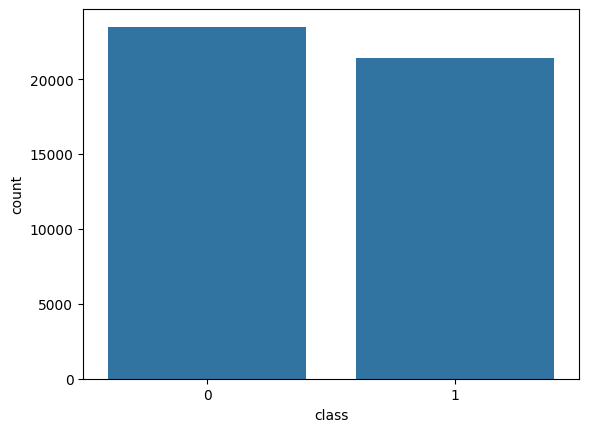

In [8]:
sns.countplot(data = data, x = 'class', order = data['class'].value_counts().index)

In [19]:
from tqdm import tqdm
import re
import nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [10]:
def preprocess_text(text_data):
    preprocessed_text = []
    
    for sentence in tqdm(text_data):
        sentence = re.sub(r'[^\w\s]', '', sentence)
        preprocessed_text.append(' '.join(token.lower()
                                  for token in str(sentence).split()
                                  if token not in stopwords.words('english')))

    return preprocessed_text


In [11]:
preprocessed_review = preprocess_text(data['text'].values)
data['text'] = preprocessed_review


100%|██████████████████████████████████████████████████████████████████████████| 44919/44919 [1:40:24<00:00,  7.46it/s]


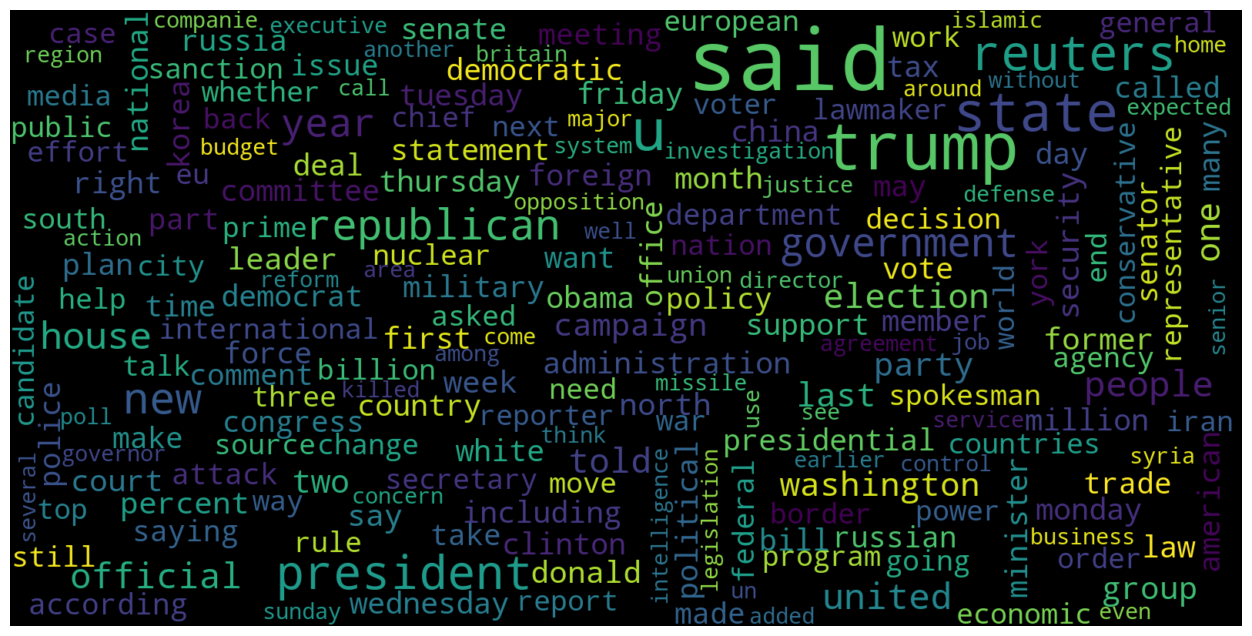

In [21]:
#Real
consolidated = ' '.join(
    word for word in data['text'][data['class'] == 1].astype(str)
    
)

wordcloud = WordCloud(width = 1600, height = 800, random_state = 42, max_font_size = 110, collocations = False)

plt.figure(figsize = (16,8))
plt.imshow(wordcloud.generate(consolidated),interpolation = 'bilinear' )
plt.axis('off')
plt.show()

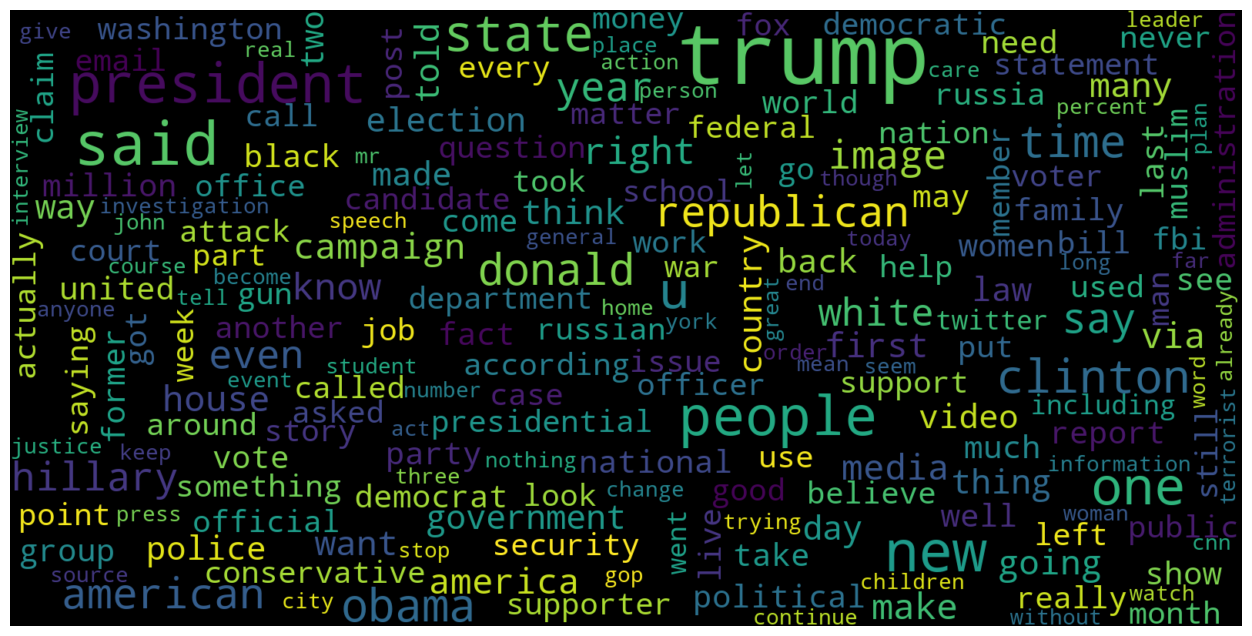

In [24]:
#Fake

consolidated = ' '.join(
    word for word in data['text'][data['class'] == 0].astype(str)
)

wordcloud = WordCloud(width = 1600, height = 800, random_state = 42, max_font_size = 110, collocations = False )

plt.figure(figsize = (16,8))
plt.imshow(wordcloud.generate(consolidated), interpolation = 'bilinear')
plt.axis('off')
plt.show()

<Axes: title={'center': 'Bar Chart of Top Words Frequency'}, xlabel='Top Words', ylabel='Count'>

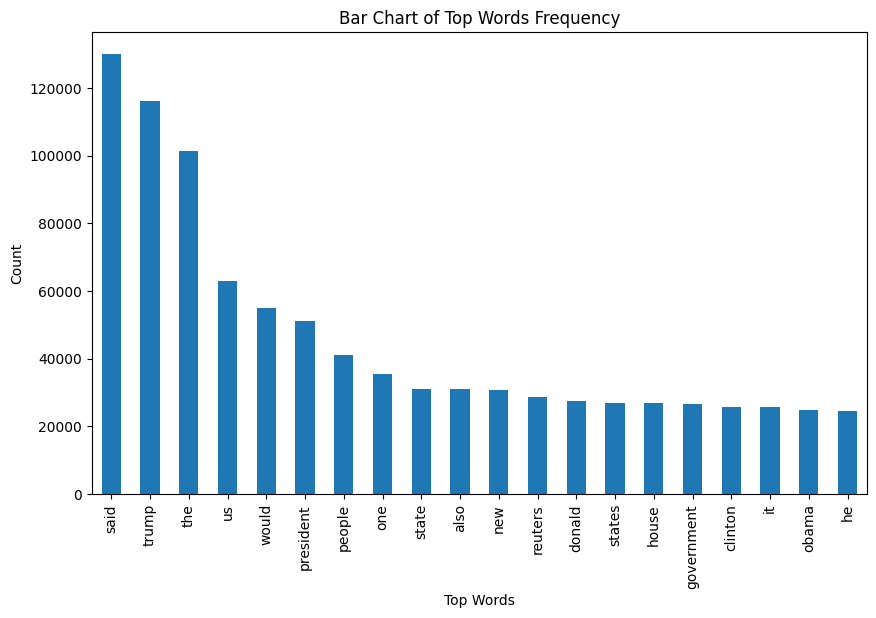

In [25]:
from sklearn.feature_extraction.text import CountVectorizer


def get_top_n_words(corpus, n=None):
    vec = CountVectorizer().fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx])
                  for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1],
                        reverse=True)
    return words_freq[:n]


common_words = get_top_n_words(data['text'], 20)
df1 = pd.DataFrame(common_words, columns=['Review', 'count'])

df1.groupby('Review').sum()['count'].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10, 6),
    xlabel="Top Words",
    ylabel="Count",
    title="Bar Chart of Top Words Frequency"
)


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(data['text'], data['class'], test_size = 0.2)




In [28]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((35935,), (8984,), (35935,), (8984,))

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer


vectorization = TfidfVectorizer()
X_train = vectorization.fit_transform(X_train)
X_test = vectorization.transform(X_test)



In [30]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)



LogisticRegression()

In [32]:

accuracy_score(y_test, model.predict(X_test))


0.9898708815672307

In [33]:
accuracy_score(y_train, model.predict(X_train))

0.9937943509113677

In [34]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(X_train, y_train)


DecisionTreeClassifier()

In [36]:
accuracy_score(y_test, model.predict(X_test))

0.9955476402493322

In [38]:
accuracy_score(y_train, model.predict(X_train))

0.999972171977181

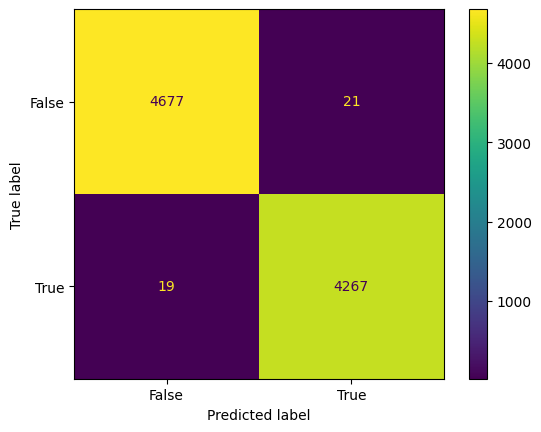

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, model.predict(X_test))

cm_display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = [False, True])


cm_display.plot()
plt.show()